# Conect to google drive

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

ModuleNotFoundError: No module named 'google.colab'

# Libraries

## External

In [2]:
!pip install -q wfdb einops
print("done!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.6/44.6 kB 5.0 MB/s eta 0:00:00
done!


In [3]:
import os
import wfdb
from matplotlib import pyplot as plt
from tqdm import tqdm
import tensorflow as tf
import seaborn as sns
import keras
from keras import layers

%matplotlib inline
sns.set_theme()

## Internal

In [4]:
import sys
sys.path.append('/content/gdrive/MyDrive/Doutorado/emg_estimator')

In [5]:
from utils.utils import *
from dataloader.dataloader import *
# from models.estimator import estimator
from models.data_augmentation import *
from models.oselm import OS_ELM

## Create paths

In [6]:
sys.path.append('/content/gdrive')

In [7]:
path = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session1"
dir_list = os.listdir(path)

path2 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session2"
dir_list2 = os.listdir(path2)

## Create the datasets

In [8]:
# import tensorflow as tf
#
# # Dados de entrada com taxa de amostragem original (100Hz)
# original_data = [...]  # Substitua pelos seus próprios dados
#
# # Taxa de amostragem original e nova taxa de amostragem desejada
# original_sampling_rate = 100
# new_sampling_rate = 2048
#
# # Fator de interpolação
# interpolation_factor = new_sampling_rate / original_sampling_rate
#
# # Converta os dados originais em um tensor TensorFlow
# original_tensor = tf.constant(original_data, dtype=tf.float32)
#
# # Calcule o novo tamanho do tensor após a interpolação
# new_size = tf.cast(tf.shape(original_tensor)[0] * interpolation_factor, tf.int32)
#
# # Realize a interpolação usando tf.image.resize
# interpolated_tensor = tf.image.resize(original_tensor[tf.newaxis, :, tf.newaxis], (new_size, 1))
#
# # Extraia os dados interpolados como um numpy array
# interpolated_data = interpolated_tensor.numpy().flatten()
#

In [9]:
import os
import wfdb
import tensorflow as tf
from utils.utils import normalize
from scipy import signal

from scipy.signal import butter, filtfilt, iirnotch

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

def synced_windows(emg_signal, force_signal, window_size=128):
    emg_samples_per_force_sample = 2048 // 100
    num_force_samples = force_signal.shape[0] - window_size
    # Calcula o número de janelas de EMG a serem geradas
    num_emg_windows = (
        emg_signal.shape[0] - window_size*emg_samples_per_force_sample
    ) // emg_samples_per_force_sample
    # Inicializa os arrays para armazenar as janelas de EMG e força
    emg_windows = tf.zeros(
        (
            num_force_samples, window_size, emg_signal.shape[1],
        )
    ).numpy()
    force_windows = tf.zeros(
        (num_force_samples, force_signal.shape[-1])
    ).numpy()
    # Amostra o sinal de EMG de acordo com a relação de frequência
    emg_step = emg_samples_per_force_sample
    for i in range(num_force_samples):
        start = i*emg_step
        end = start + window_size
        try:
            emg_windows[i] = emg_signal[start:end]
            force_windows[i] = force_signal[i + window_size // 2]
        except ValueError:
            pass
        # Atualiza o passo do EMG de acordo com a relação de frequência
        if i >= 2:
            emg_step = round(20.48)
            if i % 2 == 0:
                emg_step += 1
    dataset = tf.data.Dataset.from_tensor_slices((emg_windows, force_windows))
    return dataset

def force_data(path, force_file):
    finger_names = ["finger1", "finger2", "finger3", "finger4", "finger5"]
    # Sample rate and desired cutoff frequency (in Hz)
    fs = 100.0
    cutoff = 5.0
    for i, name in enumerate(finger_names):
        if name in force_file:
            force_signal = wfdb.rdsamp(os.path.join(path, force_file[:-4]))[0]
            force_signal = force_signal[5:]
            ######################################################
            # Filter the high frequencies
            ######################################################
            force_signal = butter_lowpass_filter(force_signal, cutoff, fs, order=4)
            return force_signal

def create_synced_datasets(path, emg_files, force_files, window_size=128):
    datasets = []
    weights_dataset = []
    for emg_file, force_file in zip(emg_files, force_files):
        emg_signal = wfdb.rdsamp(os.path.join(path, emg_file[:-4]))[0]
        indices = tf.concat([tf.range(65, 129), tf.range(193, 257)], axis=0)
        emg_signal = tf.gather(emg_signal, indices, axis=1)
        emg_signal = tf.cast(emg_signal, dtype=tf.float32)
        force_signal = force_data(path, force_file)
        finger_dataset = synced_windows(emg_signal, force_signal)
        datasets.append(finger_dataset)

    dataset = datasets[0]
    for i in range(1, len(datasets)):
        dataset = dataset.concatenate(datasets[i])
    return dataset

### Training dataset

In [10]:
emg_files_train_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
    "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_train_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
    "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_train_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
    "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_train_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
    "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_train_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
    "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_train_finger1 = [
    "1dof_force_finger1_sample1.hea",
    "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_train_finger2 = [
    "1dof_force_finger2_sample1.hea",
    "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_train_finger3 = [
    "1dof_force_finger3_sample1.hea",
    "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_train_finger4 = [
    "1dof_force_finger4_sample1.hea",
    "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_train_finger5 = [
    "1dof_force_finger5_sample1.hea",
    "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [11]:
train_dataset_f1 = create_synced_datasets(
    path, emg_files_train_finger1, force_files_train_finger1
)
train_dataset_f2 = create_synced_datasets(
    path, emg_files_train_finger2, force_files_train_finger2
)
train_dataset_f3 = create_synced_datasets(
    path, emg_files_train_finger3, force_files_train_finger3
)
train_dataset_f4 = create_synced_datasets(
    path, emg_files_train_finger4, force_files_train_finger4
)
train_dataset_f5 = create_synced_datasets(
    path, emg_files_train_finger5, force_files_train_finger5
)

In [12]:
train_dataset = train_dataset_f1.concatenate(train_dataset_f2)
train_dataset = train_dataset.concatenate(train_dataset_f3)
train_dataset = train_dataset.concatenate(train_dataset_f4)
train_dataset = train_dataset.concatenate(train_dataset_f5)

### Validation dataset

In [13]:
emg_files_val_finger1 = [
    "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_val_finger2 = [
    "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_val_finger3 = [
    "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_val_finger4 = [
    "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_val_finger5 = [
    "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_val_finger1 = [
    "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_val_finger2 = [
    "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_val_finger3 = [
    "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_val_finger4 = [
    "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_val_finger5 = [
    "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [14]:
val_dataset_f1 = create_synced_datasets(
    path, emg_files_val_finger1, force_files_val_finger1
)
val_dataset_f2 = create_synced_datasets(
    path, emg_files_val_finger2, force_files_val_finger2
)
val_dataset_f3 = create_synced_datasets(
    path, emg_files_val_finger3, force_files_val_finger3
)
val_dataset_f4 = create_synced_datasets(
    path, emg_files_val_finger4, force_files_val_finger4
)
val_dataset_f5 = create_synced_datasets(
    path, emg_files_val_finger5, force_files_val_finger5
)

In [15]:
val_dataset = val_dataset_f1.concatenate(val_dataset_f2)
val_dataset = val_dataset.concatenate(val_dataset_f3)
val_dataset = val_dataset.concatenate(val_dataset_f4)
val_dataset = val_dataset.concatenate(val_dataset_f5)

In [16]:
emg_files_test_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
]
emg_files_test_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
]
emg_files_test_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
]
emg_files_test_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
]
emg_files_test_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
]

force_files_test_finger1 = [
    "1dof_force_finger1_sample1.hea",

    "1dof_force_finger1_sample3.hea",
]
force_files_test_finger2 = [
    "1dof_force_finger2_sample1.hea",
]
force_files_test_finger3 = [
    "1dof_force_finger3_sample1.hea",
]
force_files_test_finger4 = [
    "1dof_force_finger4_sample1.hea",
]
force_files_test_finger5 = [
    "1dof_force_finger5_sample1.hea",
]

In [17]:
test_dataset_f1 = create_synced_datasets(
    path2, emg_files_test_finger1, force_files_test_finger1
)
test_dataset_f2 = create_synced_datasets(
    path2, emg_files_test_finger2, force_files_test_finger2
)
test_dataset_f3 = create_synced_datasets(
    path2, emg_files_test_finger3, force_files_test_finger3
)
test_dataset_f4 = create_synced_datasets(
    path2, emg_files_test_finger4, force_files_test_finger4
)
test_dataset_f5 = create_synced_datasets(
    path2, emg_files_test_finger5, force_files_test_finger5
)

In [18]:
test_dataset = test_dataset_f1.concatenate(test_dataset_f2)
test_dataset = test_dataset.concatenate(test_dataset_f3)
test_dataset = test_dataset.concatenate(test_dataset_f4)
test_dataset = test_dataset.concatenate(test_dataset_f5)

# Create the base model

In [19]:
# class PositionalEmbedding(layers.Layer):
#     def __init__(self, sequence_length, output_dim, **kwargs):
#         super().__init__(**kwargs)
#         self.position_embeddings = layers.Embedding(
#             input_dim=sequence_length, output_dim=output_dim
#         )
#         self.sequence_length = sequence_length
#         self.output_dim = output_dim
#
#     def call(self, inputs):
#         # The inputs are of shape: `(batch_size, frames, num_features)`
#         length = tf.shape(inputs)[1]
#         positions = tf.range(start=0, limit=length, delta=1)
#         embedded_positions = self.position_embeddings(positions)
#         return inputs + embedded_positions
#
#     def compute_mask(self, inputs, mask=None):
#         mask = tf.reduce_any(tf.cast(inputs, "bool"), axis=-1)
#         return mask
#
#
# class TransformerEncoder(layers.Layer):
#      def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
#          super().__init__(**kwargs)
#          self.embed_dim = embed_dim
#          self.dense_dim = dense_dim
#          self.num_heads = num_heads
#          self.attention = layers.MultiHeadAttention(
#              num_heads=num_heads, key_dim=embed_dim, dropout=0.3
#          )
#          self.dense_proj = keras.Sequential(
#              [layers.Dense(dense_dim, activation=tf.nn.gelu), layers.Dense(embed_dim),]
#          )
#          self.layernorm_1 = layers.LayerNormalization()
#          self.layernorm_2 = layers.LayerNormalization()
#
#      def call(self, inputs, mask=None):
#          if mask is not None:
#              mask = mask[:, tf.newaxis, :]
#
#          attention_output = self.attention(inputs, inputs, attention_mask=mask)
#          proj_input = self.layernorm_1(inputs + attention_output)
#          proj_output = self.dense_proj(proj_input)
#          return self.layernorm_2(proj_input + proj_output)
#
#
# class SignalAnalyser(tf.keras.layers.Layer):
#     def __init__(self, sequence_length, embed_dim, num_channels, **kwargs):
#         super(SignalAnalyser, self).__init__(**kwargs)
#         self.positional_embedding = PositionalEmbedding(
#             sequence_length, embed_dim * num_channels, name="frame_position_embedding"
#         )
#         self.transformer = TransformerEncoder(
#             embed_dim * num_channels, dense_dim, num_heads, name="transformer_encoder"
#         )
#         self.global_max_pooling = tf.keras.layers.GlobalMaxPooling1D()
#         self.reshape = tf.keras.layers.Reshape((16, 16, 1))
#     def call(self, inputs):
#         x = layers.Reshape((sequence_length, embed_dim * num_channels))(inputs)
#         x = self.positional_embedding(x)
#         x = self.transformer(x)
#         x = self.global_max_pooling(x)
#         x = self.reshape(x)
#         return x
#
# def signal_analyser(sequence_length=100, embed_dim=256, num_channels=1):
#     dense_dim = 8
#     num_heads = 2
#
#     inputs = keras.Input(shape=(None, None))
#     x = layers.Reshape((sequence_length, embed_dim * num_channels))(inputs)
#     x = PositionalEmbedding(
#         sequence_length,
#         embed_dim * num_channels,
#         name="frame_position_embedding"
#     )(x)
#     x = TransformerEncoder(
#         embed_dim * num_channels,
#         dense_dim,
#         num_heads,
#         name="transformer_layer"
#     )(x)
#     outputs = layers.GlobalMaxPooling1D()(x)
#
#     model = keras.Model(inputs=inputs, outputs=outputs)
#     return model

In [20]:
import tensorflow as tf
import keras
from keras import layers

###############################################
#                Transformer                  #
###############################################
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length, output_dim=output_dim,
            embeddings_regularizer='l1_l2',
        )
        self.sequence_length = sequence_length
        self.output_dim = output_dim

    def call(self, inputs):
        # The inputs are of shape: `(batch_size, frames, num_features)`
        length = tf.shape(inputs)[1]
        positions = tf.range(start=0, limit=length, delta=1)
        embedded_positions = self.position_embeddings(positions)
        return inputs + embedded_positions

    def compute_mask(self, inputs, mask=None):
        mask = tf.reduce_any(tf.cast(inputs, "bool"), axis=-1)
        return mask


class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim = embed_dim
        self.dense_dim = dense_dim
        self.num_heads = num_heads
        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embed_dim, dropout=0.3
        )
        self.dense_proj = keras.Sequential([
           layers.Dense(dense_dim, activation=tf.nn.gelu),
           layers.Dense(embed_dim, activation=tf.keras.activations.swish),
        ])
        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

    def call(self, inputs, mask=None):
        if mask is not None:
            mask = mask[:, tf.newaxis, :]

        attention_output = self.attention(
            inputs, inputs, attention_mask=mask
        )
        proj_input = self.layernorm_1(inputs + attention_output)
        proj_output = self.dense_proj(proj_input)
        return self.layernorm_2(proj_input + proj_output)

def transformer_block(sequence_length=1, embed_dim=1, num_channels=128):
    dense_dim = 4
    num_heads = 1

    inputs = keras.Input(shape=(None, None))
    x = layers.Reshape((sequence_length, embed_dim * num_channels))(inputs)
    x = PositionalEmbedding(
        sequence_length,
        embed_dim * num_channels,
        name="frame_position_embedding"
    )(x)
    x = TransformerEncoder(
        embed_dim * num_channels,
        dense_dim,
        num_heads,
        name="transformer_layer"
    )(x)
    x = layers.Reshape((sequence_length, embed_dim, num_channels))(x)

    model = keras.Model(inputs=inputs, outputs=x)
    return model

###############################################

def downsample(filters, size, apply_batchnorm=True):
  initializer = tf.random_normal_initializer(0., 0.02)

  result = tf.keras.Sequential()
  result.add(
      tf.keras.layers.Conv2D(filters, size, strides=2, padding='same',
                             kernel_initializer=initializer, use_bias=False))

  if apply_batchnorm:
    result.add(tf.keras.layers.BatchNormalization())

  result.add(tf.keras.layers.LeakyReLU())

  return result

def upsample(filters, size, apply_dropout=False):
  initializer = tf.random_normal_initializer(0., 0.02)

  result = tf.keras.Sequential()
  result.add(
    tf.keras.layers.Conv2DTranspose(filters, size, strides=2,
                                    padding='same',
                                    kernel_initializer=initializer,
                                    use_bias=False))

  result.add(tf.keras.layers.BatchNormalization())

  if apply_dropout:
      result.add(tf.keras.layers.Dropout(0.5))

  result.add(tf.keras.layers.ReLU())

  return result

down_stack = [
    downsample(64, 4, apply_batchnorm=False),  # input 128 -> (batch_size, 64, 64, 64)
    downsample(128, 4),  # (batch_size, 32, 32, 128)
    downsample(128, 4),  # (batch_size, 16, 16, 128)
    downsample(128, 4),  # (batch_size, 8, 8, 128)
    downsample(128, 4),  # (batch_size, 4, 4, 128)
    downsample(128, 4),  # (batch_size, 2, 2, 128)
    downsample(128, 4),  # (batch_size, 1, 1, 128)
  ]

up_stack = [
    upsample(128, 4, apply_dropout=True),  # (batch_size, 2, 2, 128)
    upsample(128, 4, apply_dropout=True),  # (batch_size, 4, 4, 128)
    upsample(128, 4, apply_dropout=True),  # (batch_size, 8, 8, 128)
    upsample(128, 4),  # (batch_size, 16, 16, 128)
    upsample(128, 4),  # (batch_size, 32, 32, 128)
    upsample(64, 4),  # (batch_size, 64, 64, 64)
  ]


def signal_analyser():
    trans = transformer_block()
    inputs = tf.keras.layers.Input(shape=[128, 128, 1])
    x = inputs
    # Downsampling through the model
    skips = []
    for down in down_stack:
      x = down(x)
      skips.append(x)

    skips = reversed(skips[:-1])
    x = trans(x)

    # Upsampling and establishing the skip connections
    for up, skip in zip(up_stack, skips):
      x = up(x)
      x = tf.keras.layers.Concatenate()([x, skip])

    # This is the last layer of the model
    last = tf.keras.layers.Conv2DTranspose(
        filters=1, kernel_size=3, strides=2, padding="same"
    )  # 64x64 -> 128x128

    x = last(x)
    x = tf.squeeze(x, axis=-1)
    outputs = layers.GlobalMaxPooling1D()(x)

    return tf.keras.Model(inputs=inputs, outputs=outputs)


In [21]:
analyser = signal_analyser()
analyser.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 128, 128, 1)]        0         []                            
                                                                                                  
 sequential (Sequential)     (None, 64, 64, 64)           1024      ['input_2[0][0]']             
                                                                                                  
 sequential_1 (Sequential)   (None, 32, 32, 128)          131584    ['sequential[0][0]']          
                                                                                                  
 sequential_2 (Sequential)   (None, 16, 16, 128)          262656    ['sequential_1[0][0]']        
                                                                                            

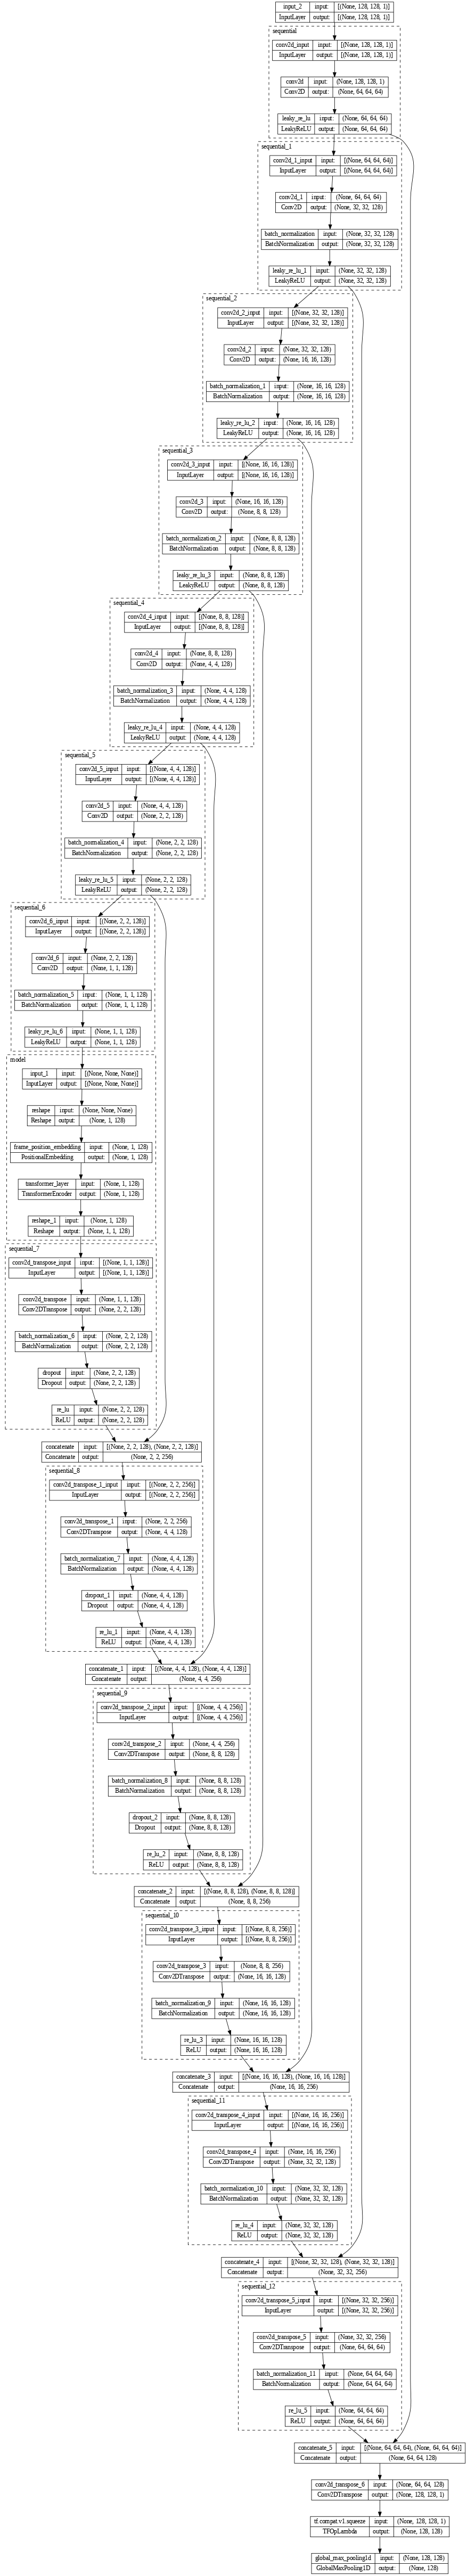

In [22]:
keras.utils.plot_model(analyser, expand_nested=True, dpi=60, show_shapes=True)

In [23]:
# Exemplo de uso
input_shape = (8, 128, 128)  # (batch, janelas, altura, largura, canal)

# Criar uma instância da classe SignalAnalyzer
analyser = signal_analyser()

# Gerar dados de exemplo
inputs = tf.random.normal(input_shape)

# Realizar a análise e remontar o sinal
output = analyser(inputs)

# Verificar a dimensão do sinal remontado
print(output.shape)

(8, 128)


In [24]:
class DeepLSTM(tf.keras.Model):
    def __init__(self, embed_dim=128, lstm_units=64, num_heads=2, dense_dim=4, num_transformer_blocks=1, num_classes=5):
        super(DeepLSTM, self).__init__()
        self.embed_dim = embed_dim
        self.lstm_units = lstm_units
        self.lstm_layer = layers.LSTM(lstm_units, return_sequences=True)
        self.attention = layers.MultiHeadAttention(
             num_heads=num_heads, key_dim=lstm_units, dropout=0.3
         )
        self.dense_proj = keras.Sequential(
            [
                layers.Dense(dense_dim, activation=tf.nn.gelu),
                layers.Dense(lstm_units),
            ]
         )
        self.output_layer = layers.Dense(num_classes, activation='linear')

    def call(self, inputs):
        x = tf.reshape(inputs, (tf.shape(inputs)[0], -1, self.embed_dim))
        lstm_output = self.lstm_layer(x)
        x = self.attention(lstm_output, lstm_output)
        x = tf.reshape(x, (tf.shape(x)[0], self.lstm_units))
        x = self.dense_proj(x)
        x = inputs
        output = self.output_layer(x)
        return output

In [25]:
# Exemplo de uso:
estimator = DeepLSTM(embed_dim=256)

# Resumo do modelo
estimator.build((None, 128))  # Defina o tamanho da entrada
estimator.summary()

Model: "deep_lstm"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 multiple                  82176     
                                                                 
 multi_head_attention_2 (Mu  multiple                  33216     
 ltiHeadAttention)                                               
                                                                 
 sequential_15 (Sequential)  (None, 64)                580       
                                                                 
 dense_6 (Dense)             multiple                  645       
                                                                 
Total params: 116617 (455.54 KB)
Trainable params: 116617 (455.54 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [26]:
def fft_tensor(input_tensor):
    # Assume que input_tensor tem o formato [batch_size, height, width, num_channels]

    # Aplicar a FFT ao longo dos eixos height e width (últimos dois eixos)
    fft_result = tf.signal.fft2d(input_tensor)

    # Dividir o resultado da FFT em parte real e imaginária
    real_part = tf.math.real(fft_result)
    imag_part = tf.math.imag(fft_result)

    # Criar um novo tensor combinando as partes real e imaginária
    complex_tensor = tf.stack([real_part, imag_part], axis=-1)

    return complex_tensor

In [27]:
# analyser = signal_analyser(sequence_length=100, embed_dim=128, num_channels=1)
analyser = signal_analyser()
estimator = DeepLSTM(embed_dim=128)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(128, 128))
latent = analyser(inputs)
outputs = estimator(latent)

estimator_real = tf.keras.Model(inputs,  outputs)

In [28]:
estimator_real.summary()

Model: "model_6"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_7 (InputLayer)        [(None, 128, 128)]        0         
                                                                 
 model_5 (Functional)        (None, 128)               4139141   
                                                                 
 deep_lstm_1 (DeepLSTM)      (None, 5)                 83849     
                                                                 
Total params: 4222990 (16.11 MB)
Trainable params: 4220046 (16.10 MB)
Non-trainable params: 2944 (11.50 KB)
_________________________________________________________________


## Model Training

### Callbacks

In [29]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_real/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/estimator_real/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [30]:
batch_size = 8

train_dataset = train_dataset.shuffle(buffer_size=len(train_dataset)).batch(batch_size)
val_dataset = val_dataset.batch(batch_size)

# Data augumentation

In [31]:
class AmplitudeScalingLayer(tf.keras.layers.Layer):
    def __init__(self, scale_range=(0.8, 1.2), seed=42, **kwargs):
        super(AmplitudeScalingLayer, self).__init__(**kwargs)
        self.scale_range = scale_range
        self.seed = seed

    def normalize(self, tensor):
        return tf.divide(
            tf.subtract(
                tensor,
                tf.reduce_min(tensor)
            ),
            tf.subtract(
                tf.reduce_max(tensor),
                tf.reduce_min(tensor)
            )
        )

    # @tf.function(jit_compile=True)
    def call(self, inputs, training=False):
        if training:
            tf.random.set_seed(self.seed)
            scale_factor = tf.random.uniform(
                shape=(1,),
                minval=self.scale_range[0],
                maxval=self.scale_range[1]
            )
            scaled_inputs = inputs * scale_factor
            return scaled_inputs
        return inputs


class TimeShiftLayer(tf.keras.layers.Layer):
    def __init__(self, max_shift, seed=42, **kwargs):
        super(TimeShiftLayer, self).__init__(**kwargs)
        self.max_shift = max_shift
        self.seed = seed

    # @tf.function(jit_compile=True)
    def call(self, inputs, training=False):
        if training:
            tf.random.set_seed(self.seed)
            # Gera um fator de deslocamento aleatório dentro do intervalo
            # permitido
            shift_factor = tf.random.uniform(
                shape=(), minval=-self.max_shift, maxval=self.max_shift
            )

            # Calcula o número de amostras para deslocar
            num_samples = tf.cast(tf.shape(inputs)[1], tf.float32)
            shift_samples = tf.cast(
                tf.round(shift_factor * num_samples), tf.int32
            )

            # Realiza o deslocamento temporal usando tf.roll
            shifted_inputs = tf.roll(inputs, shift=shift_samples, axis=1)

            return shifted_inputs
        return inputs


class PhaseRotationLayer(tf.keras.layers.Layer):
    def __init__(self, rotation_range, seed=42, **kwargs):
        super(PhaseRotationLayer, self).__init__(**kwargs)
        self.rotation_range = rotation_range
        self.seed = seed

    def get_config(self):
        config = super().get_config()
        config.update({
            "rotation_range": self.rotation_range,
        })
        return config

    # @tf.function(jit_compile=True)
    def call(self, inputs, training=False):
        if training:
            # Seta a seed para a reprodutibilidade
            tf.random.set_seed(self.seed)

            # Aplica a transformada de Fourier no sinal de entrada
            frequency_domain = tf.signal.fft(tf.cast(inputs, tf.complex64))

            # Obtém a magnitude e a fase dos componentes de frequência
            magnitude = tf.abs(frequency_domain)
            phase = tf.math.angle(frequency_domain)

            # Gera uma rotação de fase aleatória para cada componente de frequência
            rotation_factor = tf.random.uniform(shape=tf.shape(phase),
                                                minval=self.rotation_range[0],
                                                maxval=self.rotation_range[1])

            # Aplica a rotação de fase
            rotated_phase = phase + rotation_factor

            # Reconstrói os componentes de frequência com a magnitude original e a fase rotacionada
            rotated_frequency_domain = tf.complex(magnitude * tf.cos(rotated_phase),
                                                  magnitude * tf.sin(rotated_phase))

            # Aplica a transformada inversa de Fourier para obter o sinal EMG rotacionado
            rotated_signal = tf.signal.ifft(rotated_frequency_domain)

            return tf.cast(tf.math.real(rotated_signal), dtype=tf.float32)
        return inputs


class TimeMasking(tf.keras.layers.Layer):
    def __init__(self, mask_factor=0.2, seed=42):
        super(TimeMasking, self).__init__()
        self.mask_factor = mask_factor
        self.seed = seed

    # @tf.function(jit_compile=True)
    def call(self, inputs, training=False):
        if training:
            # Seta a seed para a reprodutibilidade
            tf.random.set_seed(self.seed)

            batch_size, num_canais, num_time_steps = inputs.shape

            # Determina quantos canais serão mascarados com base na porcentagem
            num_canais_mascarados = int(num_canais * self.mask_factor)

            # Gere índices aleatórios dos canais a serem mascarados
            masked_channel_indices = tf.random.shuffle(tf.range(num_canais))[:num_canais_mascarados]

            # Crie um tensor de máscara para os canais selecionados
            mask = tf.one_hot(masked_channel_indices, num_canais)

            # Aplique a máscara aos dados de entrada
            masked_inputs = inputs * (1.0 - mask[..., tf.newaxis])

            return masked_inputs

        return inputs

In [32]:
# # Criar um tensor de exemplo com a forma (8, 100, 16, 16, 1)
# input_tensor = tf.random.uniform((8, 100, 16, 16, 1), minval=0, maxval=100, dtype=tf.float32)
#
# # Criar uma instância da camada TimeMasking3D
# time_masking_layer = TimeMasking3D(mask_factor=0.2)
#
# # Aplicar a camada ao tensor de entrada
# masked_tensor = time_masking_layer(input_tensor, training=True)
#
# print("Input Tensor Shape:", input_tensor.shape)
# print("Masked Tensor Shape:", masked_tensor.shape)

In [33]:
pi = tf.constant(3.141592653589793)

#Variância do sinal de emg
variances = []
for emg, _ in train_dataset:
    var = tf.math.reduce_variance(emg)
    variances.append(var)
mean_variance = tf.reduce_mean(variances)
var = 0.1 * mean_variance
# desvio padrão do ruído gaussiano
std = tf.math.sqrt(var)

data_augmentation = tf.keras.Sequential([
    layers.GaussianNoise(stddev=0.02),
    AmplitudeScalingLayer(scale_range=(0.8, 1.2)),
    TimeShiftLayer(max_shift=0.2),
    # TimeMasking(0.2),
    PhaseRotationLayer(rotation_range=(-pi/7, pi/7)),
    # Butter(),
    layers.Dropout(0.2),
])

model_real = tf.keras.Sequential([
    # data_augmentation,
    estimator_real,
])

# Training

In [34]:
def sse(y_true, y_pred):
    return tf.reduce_sum(tf.square(y_true - y_pred))

In [35]:
def loss(signal, estimate):
    # Calcula a potência do sinal
    power = tf.reduce_sum(tf.square(signal), axis=1)

    # Pondera a função de perda de acordo com a potência
    weighted_loss = 100 * power * tf.keras.losses.mse(estimate, signal)

    return weighted_loss

In [36]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model_real.compile(optimizer=optimizer, loss=loss, metrics=['mse', 'mae', sse])
# Fit data to model

history = model_real.fit(
    train_dataset,
    epochs=200,
    validation_data=val_dataset,
    callbacks=callback,
)

Epoch 1/200


/usr/local/lib/python3.10/dist-packages/keras/src/initializers/__init__.py:144: UserWarning: The `keras.initializers.serialize()` API should only be used for objects of type `keras.initializers.Initializer`. Found an instance of type <class 'tensorflow.python.ops.init_ops_v2.RandomNormal'>, which may lead to improper serialization.
  warnings.warn(


4439/4439 [==============================] - ETA: 0s - loss: 0.0074 - mse: 0.0055 - mae: 0.0388 - sse: 0.2185
Epoch 1: val_loss did not improve from inf
4439/4439 [==============================] - 162s 34ms/step - loss: 0.0074 - mse: 0.0055 - mae: 0.0388 - sse: 0.2185 - val_loss: nan - val_mse: nan - val_mae: nan - val_sse: nan - lr: 0.0010
Epoch 2/200
4438/4439 [============================>.] - ETA: 0s - loss: 0.0030 - mse: 0.0018 - mae: 0.0294 - sse: 0.0717
Epoch 2: val_loss did not improve from inf
4439/4439 [==============================] - 162s 37ms/step - loss: 0.0030 - mse: 0.0018 - mae: 0.0294 - sse: 0.0717 - val_loss: nan - val_mse: nan - val_mae: nan - val_sse: nan - lr: 0.0010
Epoch 3/200
4438/4439 [============================>.] - ETA: 0s - loss: 0.0022 - mse: 0.0014 - mae: 0.0259 - sse: 0.0576
Epoch 3: val_loss did not improve from inf
4439/4439 [==============================] - 159s 36ms/step - loss: 0.0022 - mse: 0.0014 - mae: 0.0259 - sse: 0.0576 - val_loss: nan - 

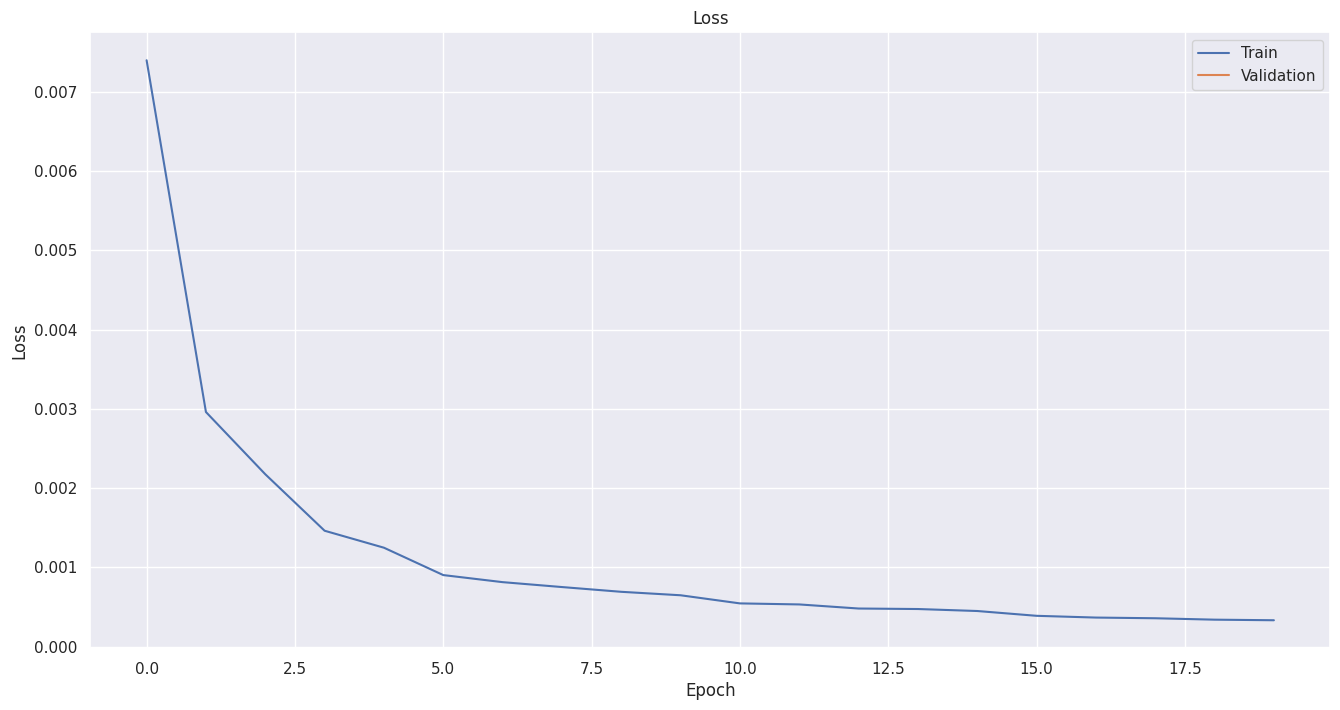

In [37]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

## Testing

In [38]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(11835, 128, 128)
(11835, 5)


In [39]:
predicted_test = estimator_real.predict(emg_signal_windows_test)

370/370 [==============================] - 9s 20ms/step


In [40]:
errors_f4 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f4)}')
print(f'variance error: {tf.math.reduce_variance(errors_f4)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: nan
variance error: nan


ValueError: ignored

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    # Increase the font size of the axes labels and ticks
    ax.tick_params(labelsize=14, ticksize=14)
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
def standard_error(y_true, y_pred):
    # Calcule os resíduos (diferença entre previsões e valores reais)
    y_true = tf.cast(y_true, dtype="float32")
    y_pred = tf.cast(y_pred, dtype="float32")
    residuals = y_true - y_pred

    # Calcule o desvio padrão dos resíduos (desvio padrão da amostra)
    std_deviation = tf.math.reduce_std(residuals)

    # Tamanho da amostra (número de exemplos)
    sample_size = tf.shape(residuals)[0]

    # Calcule o erro padrão da média
    standard_error = std_deviation / tf.math.sqrt(tf.cast(sample_size, dtype=tf.float32))

    return standard_error

In [ ]:
from scipy.signal import butter, filtfilt, iirnotch

plus_minus = "\u00B1"

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - Time Domain Input", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

In [ ]:
from scipy.signal import butter, filtfilt, iirnotch

plus_minus = "\u00B1"

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Individuo 1:  {mse_:.4f}"

for j, ax in enumerate(axes):
    mse = calc_mse(y[:, j], outputs[:, j])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, j], label='Original Force')
    ax.plot(y[:, j], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {j+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
# converter = tf.lite.TFLiteConverter.from_keras_model(estimator_real)
# converter.optimizations = [tf.lite.Optimize.DEFAULT]
# quantized_model = converter.convert()
#
# import tensorflow as tf

# Create a TFLite converter from your Keras model
converter = tf.lite.TFLiteConverter.from_keras_model(estimator_real)

# Configure the converter to use Select TF ops and disable tensor list lowering
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
converter._experimental_lower_tensor_list_ops = False

# Perform the conversion
quantized_model = converter.convert()

In [ ]:
import tensorflow as tf
import time

# Carregue o modelo TFLite a partir dos bytes
interpreter = tf.lite.Interpreter(model_content=quantized_model)

# Inicialize o interpretador
interpreter.allocate_tensors()

# Obtenha os detalhes da entrada e saída do modelo TFLite
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Prepare os dados de entrada (substitua pelos seus próprios dados)
input_data = emg_signal_windows_test

predict_test_q = []
# Defina os dados de entrada no interpretador
total_time = 0
for input in input_data:
  interpreter.set_tensor(input_details[0]['index'], tf.expand_dims(input, axis=0))
  # Execute a inferência
  start_time = time.time()
  interpreter.invoke()
  end_time = time.time()
  inference_time = end_time - start_time
  total_time += inference_time
  # Obtenha os resultados da inferência
  output_data = interpreter.get_tensor(output_details[0]['index'])
  predict_test_q.append(output_data)

In [ ]:
predicted_test = np.array(tf.squeeze(predict_test_q, axis=1))

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Individuo 1:  {mse_:.4f}"

for j, ax in enumerate(axes):
    mse = calc_mse(y[:, j], outputs[:, j])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, j], label='Original Force')
    ax.plot(y[:, j], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {j+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

# FFT

## Módulo

In [ ]:
analyser = signal_analyser(sequence_length=100, embed_dim=128, num_channels=1)
estimator = estimator = DeepLSTM(embed_dim=128)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 128))

fft_inputs = tf.cast(
    inputs, dtype=tf.complex64, name=None
)
fft_result = tf.signal.fft3d(fft_inputs)
inputs_modulo = tf.abs(fft_result)

latent = analyser(inputs_modulo)
outputs = estimator(latent)


estimator_modulo = tf.keras.Model(inputs,  outputs)

In [ ]:
model_modulo = tf.keras.Sequential([
    data_augmentation,
    estimator_modulo,
])

# Training

### Callbacks

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_modulo/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/estimator_modulo/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [ ]:
# # Compilar o modelo
# optimizer = keras.optimizers.Adam(learning_rate=1e-3)
# model_modulo.compile(optimizer=optimizer, loss='mae', metrics=['mse', sse])
# # Fit data to model
#
# history = model_modulo.fit(
#     train_dataset,
#     epochs=200,
#     validation_data=val_dataset,
#     callbacks=callback,
# )

In [ ]:
# # Plot training & validation loss values
# fig, ax = plt.subplots(figsize=(16, 8))
# ax.set_title('Loss')
# ax.plot(history.history['loss'], label = 'train')
# ax.plot(history.history['val_loss'], label = 'test')
# ax.set_ylabel('Loss')
# ax.set_xlabel('Epoch')
# ax.legend(['Train', 'Validation'])

## Testing

In [ ]:
predicted_test = estimator_modulo.predict(emg_signal_windows_test)

In [ ]:
errors_f4 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f4)}')
print(f'variance error: {tf.math.reduce_variance(errors_f4)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - Magnitude Input", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

## Phase

In [ ]:
analyser = signal_analyser(sequence_length=100, embed_dim=128, num_channels=1)
estimator = estimator = DeepLSTM(embed_dim=128)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 128))
fft_inputs = tf.cast(
    inputs, dtype=tf.complex64, name=None
)
fft_result = tf.signal.fft3d(fft_inputs)
inputs_phase = tf.math.angle(fft_result)

latent = analyser(inputs_phase)
outputs = estimator(latent)

estimator_phase = tf.keras.Model(inputs,  outputs)

In [ ]:
model_phase = tf.keras.Sequential([
    data_augmentation,
    estimator_phase,
])

# Training

### Callbacks

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_phase/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/estimator_phase/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [ ]:
# # Compilar o modelo
# optimizer = keras.optimizers.Adam(learning_rate=1e-3)
# model_phase.compile(optimizer=optimizer, loss='mae', metrics=['mse', sse])
# # Fit data to model
#
# history = model_phase.fit(
#     train_dataset,
#     epochs=200,
#     validation_data=val_dataset,
#     callbacks=callback,
# )

In [ ]:
# # Plot training & validation loss values
# fig, ax = plt.subplots(figsize=(16, 8))
# ax.set_title('Loss')
# ax.plot(history.history['loss'], label = 'train')
# ax.plot(history.history['val_loss'], label = 'test')
# ax.set_ylabel('Loss')
# ax.set_xlabel('Epoch')
# ax.legend(['Train', 'Validation'])

## Testing

In [ ]:
predicted_test = estimator_phase.predict(emg_signal_windows_test)

In [ ]:
errors_f4 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f4)}')
print(f'variance error: {tf.math.reduce_variance(errors_f4)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - Time Domain Input", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

## Complex

In [ ]:
analyser = signal_analyser(sequence_length=100, embed_dim=128, num_channels=2)
estimator = DeepLSTM(embed_dim=256)

# Define o modelo completo
inputs = tf.keras.layers.Input(shape=(100, 128))
fft_inputs = tf.cast(
    inputs, dtype=tf.complex64, name=None
)
complex_inputs = fft_tensor(fft_inputs)

latent = analyser(complex_inputs)
outputs = estimator(latent)

estimator_complex = tf.keras.Model(inputs,  outputs)

In [ ]:
model_fft = tf.keras.Sequential([
    data_augmentation,
    estimator_complex,
])

### Callbacks

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_complex/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/estimator_complex/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [ ]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model_fft.compile(optimizer=optimizer, loss=loss, metrics=['mse', 'mae', sse])
# Fit data to model

history = model_fft.fit(
    train_dataset,
    epochs=200,
    validation_data=val_dataset,
    callbacks=callback,
)

In [ ]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

## Testing

In [ ]:
predicted_test = estimator_complex.predict(emg_signal_windows_test)

In [ ]:
errors_f4 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f4)}')
print(f'variance error: {tf.math.reduce_variance(errors_f4)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

plus_minus = "\u00B1"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

In [ ]:
plus_minus = "\u00B1"

fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])
    std_derror_original = standard_error(predicted_test[:, channel], outputs[:, channel])
    std_derror_filtered = standard_error(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f} {plus_minus} {std_derror_original}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f} {plus_minus} {std_derror_filtered}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

fig.suptitle("Comparison between Original and Filtered Signals - Frequency Domain Input", fontsize=24, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

In [ ]:
from scipy.signal import butter, filtfilt, iirnotch

plus_minus = "\u00B1"

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Individuo 1:  {mse_:.4f}"

for j, ax in enumerate(axes):
    mse = calc_mse(y[:, j], outputs[:, j])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, j], label='Original Force')
    ax.plot(y[:, j], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {j+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

## Complex Dense

In [ ]:
class ComplexDense(layers.Layer):
    def __init__(self, units, activation=None, **kwargs):
        super(ComplexDense, self).__init__(**kwargs)
        self.units = units
        self.activation = tf.keras.activations.get(activation)

    def build(self, input_shape):
        real_shape = (input_shape[-1], self.units)
        imag_shape = (input_shape[-1], self.units)
        self.real_weights = self.add_weight("real_weights", shape=real_shape, initializer="random_normal", trainable=True)
        self.imag_weights = self.add_weight("imag_weights", shape=imag_shape, initializer="random_normal", trainable=True)

    def call(self, inputs):
        real_part = tf.matmul(tf.real(inputs), self.real_weights) - tf.matmul(tf.imag(inputs), self.imag_weights)
        imag_part = tf.matmul(tf.real(inputs), self.imag_weights) + tf.matmul(tf.imag(inputs), self.real_weights)
        output = tf.complex(real_part, imag_part)

        if self.activation is not None:
            output = self.activation(output)

        return output

In [ ]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length, output_dim=output_dim
        )
        self.sequence_length = sequence_length
        self.output_dim = output_dim

    def call(self, inputs):
        # The inputs are of shape: `(batch_size, frames, num_features)`
        length = tf.shape(inputs)[1]
        positions = tf.range(start=0, limit=length, delta=1)
        embedded_positions = self.position_embeddings(positions)
        return inputs + embedded_positions

    def compute_mask(self, inputs, mask=None):
        mask = tf.reduce_any(tf.cast(inputs, "bool"), axis=-1)
        return mask


class TransformerEncoder(layers.Layer):
     def __init__(self, embed_dim, dense_dim, num_heads, **kwargs):
         super().__init__(**kwargs)
         self.embed_dim = embed_dim
         self.dense_dim = dense_dim
         self.num_heads = num_heads
         self.attention = layers.MultiHeadAttention(
             num_heads=num_heads, key_dim=embed_dim, dropout=0.3
         )
         self.dense_proj = keras.Sequential(
             [ComplexDense(dense_dim, activation=tf.nn.gelu), ComplexDense(embed_dim),]
         )
         self.layernorm_1 = layers.LayerNormalization()
         self.layernorm_2 = layers.LayerNormalization()

     def call(self, inputs, mask=None):
         if mask is not None:
             mask = mask[:, tf.newaxis, :]

         attention_output = self.attention(inputs, inputs, attention_mask=mask)
         proj_input = self.layernorm_1(inputs + attention_output)
         proj_output = self.dense_proj(proj_input)
         return self.layernorm_2(proj_input + proj_output)


class SignalAnalyser(layers.Layer):
    def __init__(self, sequence_length, embed_dim, **kwargs):
        super(SignalAnalyser, self).__init__(**kwargs)
        self.positional_embedding = PositionalEmbedding(
            sequence_length, embed_dim, name="frame_position_embedding"
        )
        self.transformer = TransformerEncoder(
            embed_dim, 256, 4, name="transformer_encoder"
        )
        self.global_average_pooling = tf.keras.layers.GlobalAveragePooling1D()
        self.reshape = tf.keras.layers.Reshape((16, 16, 1))
    def call(self, inputs):
        x = layers.Reshape((100, 256))(inputs)
        x = self.positional_embedding(x)
        x = self.transformer(x)
        x = self.global_average_pooling(x)
        x = self.reshape(x)
        return x

def signal_analyser(sequence_length=100, embed_dim=256, num_channels=1):  # Add num_channels as a parameter
    dense_dim = 4
    num_heads = 1

    # inputs = keras.Input(shape=(sequence_length, embed_dim, num_channels))  # Adjust the input shape
    inputs = keras.Input(shape=(None, None))
    x = layers.Reshape((sequence_length, embed_dim * num_channels))(inputs)  # Adjust the Reshape layer
    x = PositionalEmbedding(
        sequence_length, embed_dim * num_channels, name="frame_position_embedding"
    )(x)
    x = TransformerEncoder(embed_dim * num_channels, dense_dim, num_heads, name="transformer_layer")(x)
    x = layers.GlobalMaxPooling1D()(x)
    outputs = layers.Dense(5, activation="linear")(x)

    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

# Force Filter

In [ ]:
import numpy as np
from scipy import signal

stft_result = [signal.stft(outputs[:, i], 100, nperseg=256, scaling='spectrum') for i in range(5)]

for i in range(5):
    freqs = stft_result[i][0]
    time_frames = stft_result[i][1]
    stft_data = stft_result[i][2]

    sampling_rate = 100.0
    freqs_hz = freqs * (sampling_rate / 2)

    log_magnitude = 10 * np.log10(np.abs(stft_data))

    plt.figure()
    plt.imshow(log_magnitude, cmap='jet', aspect='auto', origin='lower', extent=[time_frames.min(), time_frames.max(), freqs.min(), freqs.max()])
    plt.xlabel('Tempo (ds)')
    plt.ylabel('Frequência (Hz)')
    plt.title(f'Histograma da STFT - Dedo {i+1}')
    plt.colorbar(label='Magnitude (dB)')
    plt.show()